# IT9002 Lab 4.2: Comparing Embedding and TF-IDF Features

**Unit 04: Word Embeddings**

**IT9002 Natural Language Processing**

## Objectives

By the end of this lab, you should be able to:

- Use averaged word embeddings as features for text classification.
- Compare two feature representations using the same classifier and validation set.
- Analyze misclassified sentences to identify information lost through averaging.
- Evaluate whether combining feature representations and adjusting class weights improves performance on the weakest label.
- Use the test set for final evaluation after selecting the best configuration using the validation set.

## Data

- **Financial PhraseBank v1.0** (Malo, Sinha, Korhonen, Wallenius and Takala, 2014), the 4,217 sentences with more than 66% annotator agreement, Hugging Face `takala/financial_phrasebank`, https://huggingface.co/datasets/takala/financial_phrasebank, CC BY-NC-SA 3.0.

- The course file `financial_phrasebank.csv` (on Moodle).

- The course file `fpb_split.csv` (on Moodle), which assigns each sentence to the training, validation or test set.

- **GloVe 100d** (Pennington, Socher and Manning, 2014), 400,000 word vectors of 100 dimensions trained on Wikipedia 2014 and Gigaword 5, https://nlp.stanford.edu/projects/glove/, Public Domain Dedication and License v1.0.

- **Occupation list** (Bolukbasi, Chang, Zou, Saligrama and Kalai, 2016), https://github.com/tolga-b/debiaswe, MIT License. The course file `occupations.txt` (on Moodle) is used in Exercise 3.

- **fastText vectors for Arabic** (Grave, Bojanowski, Gupta, Joulin and Mikolov, 2018), https://fasttext.cc/docs/en/crawl-vectors.html, CC BY-SA 3.0. Exercise 4 reads the first 50,000 vectors from the fastText site.

The two files `financial_phrasebank.csv` and `fpb_split.csv` can be downloaded from Moodle. Download them to your computer, then run the cell below. If the files are already available in the runtime, the cell loads them directly, otherwise, it opens a file-upload dialog.

In [1]:
from pathlib import Path
import pandas as pd

def find(name):
    path = next((p for p in (Path(name), Path("data") / name) if p.exists()), None)
    if path is None:
        from google.colab import files
        files.upload()
        path = Path(name)
    return path

df = pd.read_csv(find("financial_phrasebank.csv"))
split = pd.read_csv(find("fpb_split.csv"))["split"]
print(df.shape, split.value_counts().to_dict())

(4217, 2) {'train': 2951, 'validation': 633, 'test': 633}


## Setup

**gensim** is used to load and query word embeddings, and **scikit-learn** to build features and train classifiers. Both are installed if they are not already available.

In [2]:
import importlib.util, subprocess, sys

for package, module in (("gensim", "gensim"), ("scikit-learn", "sklearn")):
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

Imports the libraries and tools required for the lab and displays the installed versions of **pandas**, **NumPy**, **gensim**, and **scikit-learn**.

In [3]:
import collections
import numpy as np
import matplotlib.pyplot as plt
import gensim
import gensim.downloader as api
import sklearn
from gensim.models import KeyedVectors
from scipy.sparse import csr_matrix, hstack
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, f1_score

print("pandas", pd.__version__, "| NumPy", np.__version__, "| gensim", gensim.__version__, "| scikit-learn", sklearn.__version__)

pandas 3.0.2 | NumPy 2.4.2 | gensim 4.4.0 | scikit-learn 1.9.1


## 1. Establishing the TF-IDF Starting Point

The starting point is logistic regression on **TF-IDF** features with the default settings, trained on the training set and evaluated on the validation set.

It is built in three steps:

- The three sets are separated with the saved split.

- The vectorizer is fitted on the training set and converts all three sets.

- The model is trained, and its classification report on the validation set is displayed.

In [4]:
LABELS = ["negative", "neutral", "positive"]
train, val, test = (df[split == name] for name in ("train", "validation", "test"))

tv = TfidfVectorizer()
T_train, T_val, T_test = tv.fit_transform(train["sentence"]), tv.transform(val["sentence"]), tv.transform(test["sentence"])
lr_tfidf = LogisticRegression(max_iter=1000).fit(T_train, train["label"])
pred_tfidf = lr_tfidf.predict(T_val)
print(T_train.shape)
print(classification_report(val["label"], pred_tfidf, labels=LABELS, digits=3))

(2951, 7596)
              precision    recall  f1-score   support

    negative      0.900     0.351     0.505        77
     neutral      0.761     0.961     0.849       381
    positive      0.770     0.537     0.633       175

    accuracy                          0.769       633
   macro avg      0.810     0.616     0.662       633
weighted avg      0.780     0.769     0.748       633



Each sentence is represented by **7,596** TF-IDF values, one for each term in the training vocabulary.

The macro F1 is **0.662**, and the **weakest label** is negative, with an F1 of **0.505**.

## 2. Building Averaged Embedding Features

A classifier needs one vector for each sentence, while an embedding model provides one vector for each word.

**Averaging** the word vectors produces a single **document vector** for the sentence:

$$\text{document vector} = \frac{v_1 + v_2 + \dots + v_n}{n}$$

$v_1$ to $v_n$ are the vectors of the $n$ words in the sentence that have a vector.

The pretrained **GloVe** vectors of 100 dimensions are loaded first. The first run downloads **128 MB**.

In [5]:
glove = api.load("glove-wiki-gigaword-100")
print(len(glove.index_to_key), "words |", glove.vector_size, "dimensions")

400000 words | 100 dimensions


A pretrained model has a vector only for the words in its own vocabulary, so the **coverage** of the training sentences is measured first.

`build_analyzer()` returns the function that the vectorizer uses to split a sentence into tokens, so that both representations work on the same tokens.

The terms in the training vocabulary and the tokens in the training sentences that have no pretrained vector are counted.

In [6]:
analyzer = tv.build_analyzer()
tokens = [token for sentence in train["sentence"] for token in analyzer(sentence)]
missing_terms = [term for term in tv.vocabulary_ if term not in glove.key_to_index]
missing_tokens = [token for token in tokens if token not in glove.key_to_index]
print("terms without a vector:", len(missing_terms), "of", len(tv.vocabulary_))
print("tokens without a vector:", len(missing_tokens), "of", len(tokens))
print(collections.Counter(missing_tokens).most_common(8))

terms without a vector: 1017 of 7596
tokens without a vector: 2006 of 58362
[('eur0', 48), ('basware', 28), ('ruukki', 28), ('aspo', 23), ('eur1', 21), ('outotec', 20), ('teleste', 19), ('aldata', 19)]


**1,017** of the 7,596 terms have no vector, which is 13.4% of the vocabulary.

They account for only **2,006** of the 58,362 tokens, or 3.4%, because most of them are rare company names such as `basware` and `ruukki`.

The average is calculated for the 3 words `net`, `profit`, and `rose`, on the first 3 of the 100 positions.

In [7]:
example = ["net", "profit", "rose"]
table = pd.DataFrame([glove[word][:3] for word in example], index=example, columns=["first", "second", "third"])
table.loc["average"] = table.mean()
table.round(2)

,first,second,third
net,0.51,0.06,0.70
profit,0.68,0.43,-0.11
rose,1.09,0.82,-0.19
average,0.76,0.44,0.13


The first position of the average is:

$$\frac{0.51 + 0.68 + 1.09}{3} = 0.76$$

The other 99 positions are averaged in the same way.

`average()` returns one averaged vector for each sentence. *Tokens without a pretrained vector are skipped*.

Its parameters are:

- `sentences`: the sentences to convert.

- `stop_words` (default `False`): when `True`, the words on scikit-learn's English stop list are removed before averaging.

- `idf` (default `None`): a dictionary that gives a weight for each term, such as its IDF value. When it is given, the average becomes a **weighted average**, so that rare terms contribute more.

With the weights $w_1$ to $w_n$ of the $n$ words, the weighted average is:

$$\text{document vector} = \frac{w_1 v_1 + w_2 v_2 + \dots + w_n v_n}{w_1 + w_2 + \dots + w_n}$$

In [8]:
def average(sentences, stop_words=False, idf=None):
    features = np.zeros((len(sentences), glove.vector_size), dtype=np.float32)
    for row, sentence in enumerate(sentences):
        tokens = [t for t in analyzer(sentence) if t in glove.key_to_index]
        if stop_words:
            tokens = [t for t in tokens if t not in ENGLISH_STOP_WORDS]
        if idf is not None:
            tokens = [t for t in tokens if t in idf]
        if tokens:
            weights = None if idf is None else [idf[t] for t in tokens]
            features[row] = np.average([glove[t] for t in tokens], axis=0, weights=weights)
    return features

E_train, E_val, E_test = average(train["sentence"]), average(val["sentence"]), average(test["sentence"])
print(E_train.shape)

(2951, 100)


Each sentence is now represented by **100** values, whatever its length, in place of 7,596.

## 3. Comparing the Two Representations

The comparison is fair when everything except the features stays the same: the same classifier, the same settings, the same training sentences, and the same validation sentences.

Logistic regression is trained on the averaged embeddings, and its classification report on the validation set is displayed.

In [9]:
lr_emb = LogisticRegression(max_iter=1000).fit(E_train, train["label"])
pred_emb = lr_emb.predict(E_val)
print(classification_report(val["label"], pred_emb, labels=LABELS, digits=3))

              precision    recall  f1-score   support

    negative      0.532     0.325     0.403        77
     neutral      0.773     0.919     0.839       381
    positive      0.684     0.520     0.591       175

    accuracy                          0.736       633
   macro avg      0.663     0.588     0.611       633
weighted avg      0.719     0.736     0.718       633



The macro F1 is **0.611**, against 0.662 for TF-IDF, and the F1 of negative falls from 0.505 to **0.403**. On this corpus, the averaged embeddings give a weaker classifier than TF-IDF.

The F1 of each label is plotted for the two representations as grouped bars, with the values in a table below the plot.

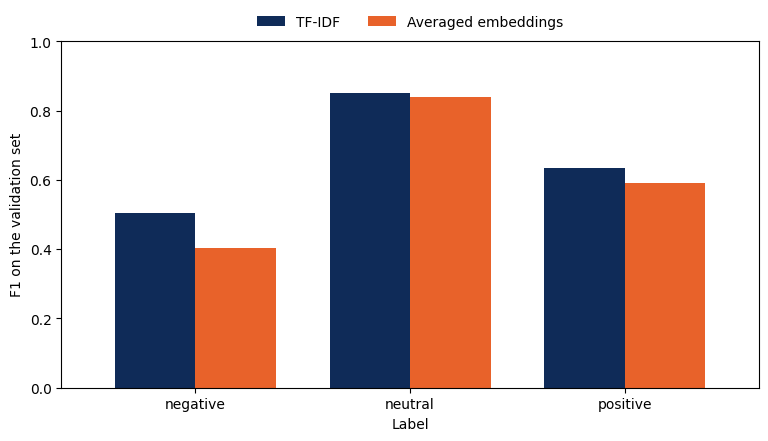

,TF-IDF,Averaged embeddings
negative,0.505,0.403
neutral,0.849,0.839
positive,0.633,0.591


In [10]:
NAVY, TEAL, ORANGE = "#0F2B58", "#2A9DB5", "#E8622A"
f1 = pd.DataFrame({"TF-IDF": f1_score(val["label"], pred_tfidf, labels=LABELS, average=None),
                   "Averaged embeddings": f1_score(val["label"], pred_emb, labels=LABELS, average=None)}, index=LABELS)
ax = f1.plot.bar(figsize=(9, 4.5), width=0.75, color=[NAVY, ORANGE], rot=0)
ax.set_xlabel("Label")
ax.set_ylabel("F1 on the validation set")
ax.set_ylim(0, 1)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
plt.show()
f1.round(3)

The difference is smallest on neutral, 0.849 against 0.839, and largest on **negative**, the label with the fewest training sentences.

The two confusion matrices are plotted side by side, with the actual labels as rows and the predicted labels as columns.

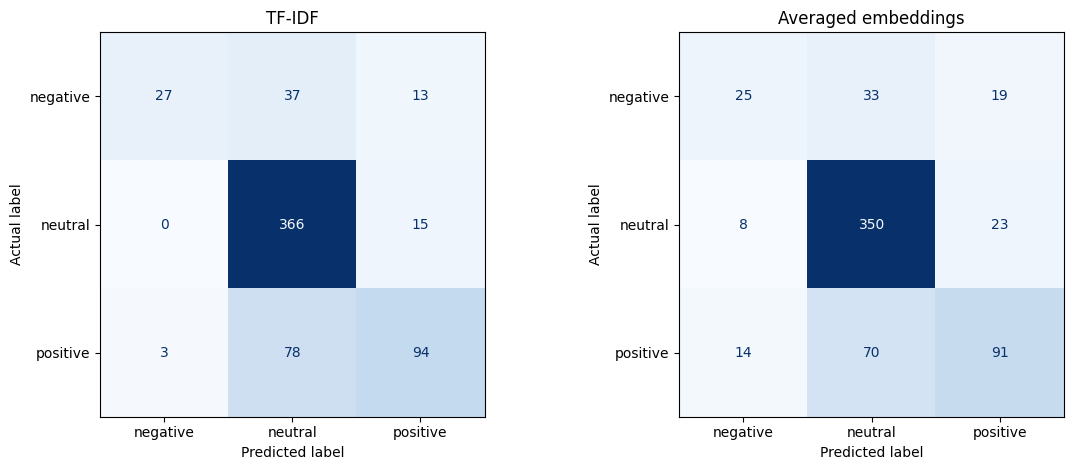

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (name, pred) in zip(axes, (("TF-IDF", pred_tfidf), ("Averaged embeddings", pred_emb))):
    ConfusionMatrixDisplay.from_predictions(val["label"], pred, labels=LABELS, cmap="Blues", colorbar=False, ax=ax)
    ax.set(title=name, xlabel="Predicted label", ylabel="Actual label")
plt.tight_layout()
plt.show()

Both classifiers identify a similar number of the 77 negative sentences, 27 and 25.

The difference is in the negative column: TF-IDF labels **3** sentences of other labels as negative, while the averaged embeddings label **22**, of which 14 are positive.

## 4. Analyzing the Difference Between the Representations

The two classifiers do not fail on the same sentences.

The validation sentences are counted in 4 groups: labeled correctly by both classifiers, by TF-IDF only, by the averaged embeddings only, or by neither.

In [12]:
actual = val["label"].values
correct_tfidf, correct_emb = pred_tfidf == actual, pred_emb == actual
print("both correct:", (correct_tfidf & correct_emb).sum())
print("only TF-IDF correct:", (correct_tfidf & ~correct_emb).sum())
print("only embeddings correct:", (~correct_tfidf & correct_emb).sum())
print("neither correct:", (~correct_tfidf & ~correct_emb).sum())

both correct: 436
only TF-IDF correct: 51
only embeddings correct: 30
neither correct: 116


**51** sentences are labeled correctly by TF-IDF alone and **30** by the averaged embeddings alone.

Each representation therefore holds information that the other lacks.

The first list displays the 8 sentences that only TF-IDF labels correctly and that the embedding classifier labels with the highest probability.

In [13]:
results = val.assign(tfidf=pred_tfidf, embeddings=pred_emb,
                     p_embeddings=lr_emb.predict_proba(E_val).max(axis=1), p_tfidf=lr_tfidf.predict_proba(T_val).max(axis=1))
only_tfidf = results[correct_tfidf & ~correct_emb].sort_values("p_embeddings", ascending=False)
for row, r in only_tfidf.head(8).iterrows():
    print(f"{row:>5} {r['label']:>8} | embeddings: {r['embeddings']:<8} {r['p_embeddings']:.2f} | {r['sentence']}")

 3785  neutral | embeddings: negative 0.95 | zip , '' experts warned Tuesday .
 3918  neutral | embeddings: positive 0.87 | Amer , which bought Salomon from adidas in October , said the job cuts are aimed at boosting competitiveness .
 1160  neutral | embeddings: negative 0.78 | The EUR 0.7 million non-recurring expenses have been recorded for the third quarter .
 3231  neutral | embeddings: negative 0.78 | Profit after taxes totaled EUR 12.1 mn .
 1204  neutral | embeddings: positive 0.77 | The shipyard hopes the regional government in Andalusia can offer its some form of financial support .
  729 positive | embeddings: neutral  0.69 | Cash flow from operating activities is estimated to be positive .
 2651  neutral | embeddings: positive 0.68 | Rautalinko was resposnible also for Mobility Services , and his job in this division will be continued by Marek Hintze .
  329 positive | embeddings: negative 0.68 | October-December sales were 302 mln eur , or a 25.3 pct increase year on year 

The second list displays the 8 sentences that only the averaged embeddings label correctly and that the TF-IDF classifier labels with the highest probability.

In [14]:
only_emb = results[~correct_tfidf & correct_emb].sort_values("p_tfidf", ascending=False)
for row, r in only_emb.head(8).iterrows():
    print(f"{row:>5} {r['label']:>8} | TF-IDF: {r['tfidf']:<8} {r['p_tfidf']:.2f} | {r['sentence']}")

 1226 positive | TF-IDF: neutral  0.80 | We warmly welcome him to Satama '' , states Jussi Lansio , chairman of the Board .
  637 positive | TF-IDF: neutral  0.75 | Okmetic 's products are based on high-tech expertise that generates added value for customers , innovative product development and an extremely efficient production process .
 2872 negative | TF-IDF: neutral  0.72 | The reduction notice applied to 17 people .
  477 positive | TF-IDF: neutral  0.72 | Significance : Teleste has emphasised that with its large size and growing economy , as well as the rapid development of its TV services distribution industry , Poland is viewed as an attractive market .
  700 positive | TF-IDF: neutral  0.72 | `` Stonesoft sees great promise in the future of IPv6 .
 1466 positive | TF-IDF: neutral  0.71 | `` I 'm pleased to receive the Nomination Committee 's request and confidence , '' says Jon Risfelt .
 1661 positive | TF-IDF: neutral  0.71 | In China , Finnish Kone that provides elevators ,

In this corpus, the label often depends on the direction of a change.

The cosine similarity is displayed for 3 pairs of words with opposite directions.

In [15]:
for first, second in (("increase", "decrease"), ("rose", "fell"), ("up", "down")):
    print(f"{first}, {second}: {glove.similarity(first, second):.3f}")

increase, decrease: 0.881
rose, fell: 0.883
up, down: 0.916


The 3 values are **0.881**, **0.883**, and **0.916**. Opposites appear in the same contexts, so an average that contains `increase` is almost the same as one that contains `decrease`.

In TF-IDF, the two words are separate columns with separate coefficients.

Complete the following table with **3 sentences** from the two lists, at least one from each.

In the **Explanation** column, state which words lead one representation to the correct label and why the other representation misses it.

| Sentence | Actual label | TF-IDF | Averaged embeddings | Explanation |
|---|---|---|---|---|
| &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp; |
| &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp; |
| &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp; |

## 5. Selecting a Feature Representation

**Task:** The classifier should identify the negative sentences better than the TF-IDF starting point, without lowering the macro F1.

**Corpus:** The 2,951 training sentences train every candidate, and the 633 validation sentences evaluate it.

Change one decision at a time and evaluate its effect on the validation set. The candidates are:

- **Stop-word removal:** `average(..., stop_words=True)` leaves the stop words out of the average.

- **IDF weighting:** `average(..., idf=idf)` gives rare terms more weight in the average.

- **Class weights:** `class_weight="balanced"` makes a classification error on a rare label cost more during training.

- **Combined features:** the TF-IDF columns and the 100 averaged columns are placed side by side, so that the classifier can use both.

The selected configuration should satisfy two requirements:

- The macro F1 on the validation set should be **at least 0.70**.

- The F1 of the negative label on the validation set should be **at least 0.60**.

Then provide evidence for the selected configuration:

- The F1 of each label and the macro F1 for every candidate and for the selected configuration.

- The number of columns of each candidate's features.

- The completed decision table.

The investigation uses one dictionary and two functions:

- `idf` gives the IDF value that the vectorizer learned for each term in the training vocabulary.

- `combine()` places a TF-IDF matrix and a matrix of averaged embeddings side by side.

- `evaluate()` trains logistic regression with the given class weights on the given training features. It returns the number of columns, the F1 of each label, and the macro F1 on the validation set.

In [16]:
idf = dict(zip(tv.get_feature_names_out(), tv.idf_))

def combine(tfidf_matrix, embedding_matrix):
    return hstack([tfidf_matrix, csr_matrix(embedding_matrix)]).tocsr()

def evaluate(X_train, X_val, class_weight=None):
    model = LogisticRegression(max_iter=1000, class_weight=class_weight)
    model.fit(X_train, train["label"])
    scores = f1_score(val["label"], model.predict(X_val), labels=LABELS, average=None)
    return {"columns": X_train.shape[1], **dict(zip(LABELS, np.round(scores, 3).tolist())),
            "macro F1": float(np.round(scores.mean(), 3))}

print(evaluate(T_train, T_val))
print(evaluate(E_train, E_val))

{'columns': 7596, 'negative': 0.505, 'neutral': 0.849, 'positive': 0.633, 'macro F1': 0.662}
{'columns': 100, 'negative': 0.403, 'neutral': 0.839, 'positive': 0.591, 'macro F1': 0.611}


In [17]:
# TODO: Evaluate each candidate change on its own, then combinations of the changes that help, and print one row per configuration.


**Expected results:**

- **Stop-word removal:** macro F1 rises to about **0.654** and negative F1 to about 0.500, because the average is no longer dominated by words that carry no sentiment.

- **IDF weighting:** macro F1 rises to about **0.645** and negative F1 to about 0.460.

- **Class weights:** negative F1 rises to about **0.537**, with a macro F1 of about 0.648.

- **Combined features:** macro F1 rises to about **0.692**, above both representations on their own, with a negative F1 of about 0.537.

- No single change meets both requirements. **Combined features with class weights** give a macro F1 of about **0.732** and a negative F1 of about **0.638**, which meets both.

Complete the following table with **one row** for each candidate change.

In the **Reason** column, support each decision with evidence from the F1 values.

| Change | Macro F1 | Negative F1 | Decision | Reason |
|---|---|---|---|---|
| TF-IDF starting point | 0.662 | 0.505 | | |
| Averaged embeddings | 0.611 | 0.403 | | |
| Stop-word removal | | | | |
| IDF weighting | | | | |
| Class weights | | | | |
| Combined features | | | | |
| Selected configuration | | | | |

### Comparing the Selected Configuration Across Labels

The configuration with combined features and class weights is trained, and its F1 scores are added to the table of section 3.

The three configurations are plotted as grouped bars.

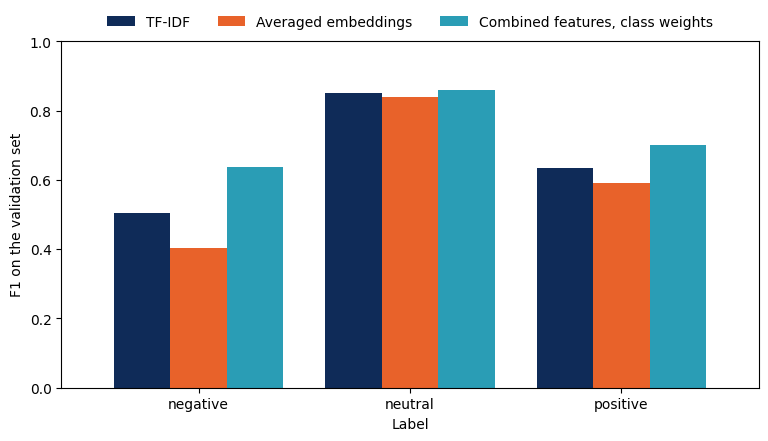

,TF-IDF,Averaged embeddings,"Combined features, class weights"
negative,0.505,0.403,0.638
neutral,0.849,0.839,0.858
positive,0.633,0.591,0.700


In [18]:
C_train, C_val, C_test = combine(T_train, E_train), combine(T_val, E_val), combine(T_test, E_test)
selected = LogisticRegression(max_iter=1000, class_weight="balanced").fit(C_train, train["label"])
f1["Combined features, class weights"] = f1_score(val["label"], selected.predict(C_val), labels=LABELS, average=None)
ax = f1.plot.bar(figsize=(9, 4.5), width=0.8, color=[NAVY, ORANGE, TEAL], rot=0)
ax.set_xlabel("Label")
ax.set_ylabel("F1 on the validation set")
ax.set_ylim(0, 1)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
plt.show()
f1.round(3)

The combined configuration has the highest F1 on every label. The gain is largest on negative, from 0.505 to **0.638**, while neutral changes least.

## 6. Final Evaluation on the Test Set

Each configuration is evaluated **once** on the test set, after every choice has been made on the validation set.

The majority baseline is added as the reference.

Four classifiers are evaluated on the 633 test sentences, and their accuracy, macro F1, and negative F1 are displayed.

In [19]:
baseline = DummyClassifier(strategy="most_frequent").fit(T_train, train["label"])
rows = []
for name, model, X in (("Majority baseline", baseline, T_test),
                       ("TF-IDF", lr_tfidf, T_test),
                       ("Averaged embeddings", lr_emb, E_test),
                       ("Combined features, class weights", selected, C_test)):
    pred = model.predict(X)
    scores = f1_score(test["label"], pred, labels=LABELS, average=None)
    rows.append((name, round(accuracy_score(test["label"], pred), 3), round(float(scores.mean()), 3), round(float(scores[0]), 3)))
comparison = pd.DataFrame(rows, columns=["features", "accuracy", "macro F1", "negative F1"])
comparison

,features,accuracy,macro F1,negative F1
0,Majority baseline,0.602,0.250,0.000
1,TF-IDF,0.766,0.667,0.522
2,Averaged embeddings,0.717,0.607,0.426
3,"Combined features, class weights",0.773,0.734,0.663


On the test set, TF-IDF gives a macro F1 of **0.667** and the averaged embeddings **0.607**. The order on the validation set therefore holds on unseen sentences.

The combined configuration gives about **0.73**, with a negative F1 of **0.663** against 0.522 for TF-IDF.

The test accuracy and the test macro F1 of the four classifiers are plotted side by side.

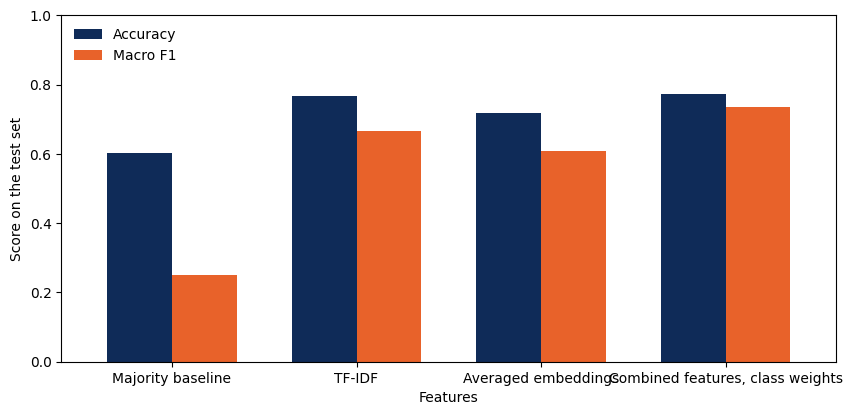

In [20]:
ax = comparison.set_index("features")[["accuracy", "macro F1"]].plot.bar(figsize=(10, 4.5), width=0.7, color=[NAVY, ORANGE], rot=0)
ax.set_xlabel("Features")
ax.set_ylabel("Score on the test set")
ax.set_ylim(0, 1)
ax.legend(["Accuracy", "Macro F1"], loc="upper left", frameon=False)
plt.show()

The averaged embeddings stay above the majority baseline and below TF-IDF on both measures.

In short sentences where the label depends on single words, a separate column for each word is hard to beat, and the embeddings help most as an addition.

## Exercises

### Exercise 1: Terms Unseen in Training

A TF-IDF model ignores every term that is missing from its training vocabulary.

Count the **terms in the test set** that are missing from the training vocabulary, and how many of them have a pretrained vector.

In [21]:
# TODO: Count the test terms that are missing from the training vocabulary, and how many of them have a pretrained vector.


**Expected result:** **887** terms in the test set are missing from the training vocabulary, and **717** of them have a pretrained vector.

The averaged embeddings can therefore use words that the TF-IDF model has never seen.

### Exercise 2: Similar Sentences with Opposite Labels

Find the **positive** and the **negative** training sentence with the highest cosine similarity between their averaged vectors.

Report:

- The 2 sentences.

- The cosine similarity between their averaged vectors.

- The cosine similarity between their TF-IDF vectors.

In [22]:
# TODO: Print the most similar pair of a positive and a negative training sentence under averaged embeddings, and its TF-IDF cosine similarity.


**Expected result:** The pair is `Operating profit rose to EUR 27.8 mn from EUR 17.5 mn in 2008 .` and `Operating profit fell to EUR 15.1 mn from EUR 24.6 mn in 2006 .`, with a cosine similarity of **0.997** under averaged embeddings and **0.544** under TF-IDF.

The 2 sentences differ in one word and in their numbers, and the vectors of `rose` and `fell` are almost the same.

### Exercise 3 (Extension): Occupations and Gender

Word embeddings learn the associations in their training text, including social stereotypes. This is known as **bias** in word embeddings.

The course file `occupations.txt` lists 291 occupations.

For every occupation in the file, find the word that relates to `woman` as the occupation relates to `man`, with `most_similar(positive=[occupation, "woman"], negative=["man"], topn=1)`.

Report:

- The answers for **12 occupations**: `doctor`, `manager`, `plumber`, `janitor`, `programmer`, `carpenter`, `lawyer`, `mechanic`, `scientist`, `surgeon`, `banker`, and `chef`.

- The 5 most frequent answers over the whole file.

- In a Markdown cell, the **5 results** that most clearly replace an occupation with one that the training text associates with women.

In [23]:
# TODO: Answer the analogy man : occupation, woman : ? for every occupation, and print the 12 named answers and the 5 most frequent answers.


**Expected results:**

- `doctor` gives `nurse`, `manager` gives `assistant`, `plumber` gives `manicurist`, `janitor` gives `schoolteacher`, and `programmer` gives `educator`.

- `lawyer` gives `attorney` and `scientist` gives `researcher`, which are neutral.

- Over the whole file, the most frequent answers are `businesswoman` for 9 occupations, `urologist` for 6, and `novelist` and `housekeeper` for 5 each.

An application that uses the vectors inherits these associations.

### Exercise 4 (Extension): Occupations and Gender in Arabic

Repeat the analogy of Exercise 3 on pretrained **fastText vectors for Arabic**.

The address of the vectors and 20 occupations in their masculine form, such as `طبيب` (doctor) and `مهندس` (engineer), are defined first.

In [24]:
ARABIC_VECTORS = "https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.ar.300.vec.gz"
occupations_ar = ["طبيب", "مهندس", "معلم", "مدير", "محاسب", "باحث", "صحفي", "ممثل", "مصمم", "وزير",
                  "رئيس", "أستاذ", "موظف", "شاعر", "لاعب", "مدرب", "مترجم", "مؤلف", "مخرج", "فنان"]
print(len(occupations_ar), "occupations")

20 occupations


Load the first **50,000 vectors** with `KeyedVectors.load_word2vec_format(ARABIC_VECTORS, binary=False, limit=50000)`, which reads about 50 MB.

For each occupation, display the word that relates to `امرأة` (woman) as the occupation relates to `رجل` (man).

In a Markdown cell, compare the answers with those of Exercise 3.

In [25]:
# TODO: Load the first 50,000 Arabic vectors and print the answer of the analogy for the 20 occupations.


**Expected result:** **18** of the 20 answers are the feminine form of the same occupation, such as `طبيبة` for `طبيب` and `مهندسة` for `مهندس`.

Arabic marks gender on the word itself, so the analogy mostly returns the same occupation, which the English vectors could not do.

The 2 other answers replace the occupation: `محاسب` (accountant) gives `سكرتيرة` (secretary) and `مخرج` (director) gives `ممثلة` (actress).